# Figure 7 -- characterizability across the mass--period plane (`characterizability_joint_kepmodel_3class_noundet`)

Each companion of the four injected populations, coloured by what the `kepmodel` periodogram
established about its period, with stacked class histograms on both margins and the
$\mathrm{SNR_{tot}}$ loci drawn over each panel. The three classes are **data-only** -- no truth
column is read, so the identical classification can be run on real DR4 epoch astrometry:

| class | colour | meaning |
| --- | --- | --- |
| no significant peak or acceleration | grey | neither channel clears the threshold calibrated on the companion-free control at a 1\% false-positive rate |
| significant peak, period localized | indigo | the periodogram channel clears its threshold **and** the competitive region spans $< 0.05$ dex |
| significant peak or acceleration, period not localized | violet | the competitive region is wide, or the significance comes from the acceleration channel alone |

The inputs are the characterization tables in `catalog/periodograms/` -- one row per system,
written by the cluster run of the `kepmodel` search over every system in the catalog -- and
`calibration.json`, the thresholds that run measured on the companion-free control. The
classification, the loci and the figure are `epochalypse_figures.py`'s, carried into `paperfig.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The characterization tables

Five population keys, three files: the high-SNR populations are a row selection
($\mathrm{SNR_{tot}} \ge 5$ on every companion) of the same tables, not a separate run.
`load_chars` renames the generator's columns onto the figure vocabulary (`sma_k -> a_k_au`,
`mass_pl_k` [$M_{\rm Jup}$] `-> Mp_k_msun`, `inc_k -> i_k_rad`) and applies the calibrated flags.

In [2]:
MAN, CAL = pf.manifest(), pf.calibration()
print(f"run written {MAN['written']} on {MAN['n_ranks']} ranks, code version {MAN['version']}")
print(f"grid: {MAN['grid']['n_periods']:,} trial periods, "
      f"{MAN['grid']['p_min_yr']:.2e} - {MAN['grid']['p_max_yr']:.0f} yr over {MAN['grid']['n_segments']} segments")
print("classifier:", ", ".join(f"{k}={v}" for k, v in MAN["classifier"].items()))
assert MAN["classifier"]["width_constrained_dex"] == pf.WIDTH_THR

KEYS = ["1_companion", "2_companion", "1_companion_high_snr", "2_companion_high_snr"]
chars = {key: pf.load_chars(key) for key in KEYS}

run written 2026-10-26T19:57:39-0400 on 960 ranks, code version 0.1.0
grid: 15,777 trial periods, 1.30e-03 - 3700 yr over 32 segments
classifier: delta_bic_detect=10.0, delta_power_unimodal=10.0, min_separation_dex=0.1, width_delta=4.0, width_constrained_dex=0.05, edge_frac=0.02, period_recover_tol=1.2


  1_companion            5,040,328 systems   characterization_1_companion.parquet


  2_companion            5,040,328 systems   characterization_2_companion.parquet
  1_companion_high_snr     436,883 systems   characterization_1_companion_high_snr.parquet   (SNR_tot >= 5 view)
  2_companion_high_snr      25,946 systems   characterization_2_companion_high_snr.parquet   (SNR_tot >= 5 view)


## 2. The detection thresholds, from the companion-free control

The periodogram $\Delta\chi^2$ is maximized over 15,777 trial periods, so under the null it is
inflated by the look-elsewhere effect and is not $\chi^2_4$-distributed; it is further inflated
because the catalog injects scatter at the $\sigma_{\rm UEVA}$ scale but reports the smaller
$\sigma_{\rm formal}$. The thresholds are therefore *measured*: the quantiles of the `0_companion`
population that leave a 1\% total false-positive rate, split evenly between the periodogram-peak
and acceleration channels. `calibration.json` carries them; they are re-derived here from the
control table as a check.

In [3]:
TARGET_FP = 0.01
assert abs(CAL["target_fp"] - TARGET_FP) < 1e-12
thr_orbit, thr_accel = CAL["thr_orbit"], CAL["thr_accel"]
print(f"thresholds from {CAL['n_null_systems']:,} companion-free systems @ FP = {TARGET_FP:.0%}:")
print(f"  orbit Delta-chi2 > {thr_orbit:6.1f}   (null rate {CAL['realized_fp_peak']:.3%})")
print(f"  accel Delta-chi2 > {thr_accel:6.1f}   (null rate {CAL['realized_fp_accel']:.3%})")
print(f"  either channel   :          {CAL['realized_fp']:.3%} of the null")

null = pd.read_parquet(pf.char_path("0_companion"), columns=["top_power", "accel_delta_chi2"])
q = 100 * (1 - TARGET_FP / 2)
_o, _a = np.nanpercentile(null["top_power"], q), np.nanpercentile(null["accel_delta_chi2"], q)
print(f"\nre-derived here from {len(null):,} rows: orbit {_o:.2f} (file {thr_orbit:.2f}), "
      f"accel {_a:.2f} (file {thr_accel:.2f})")
assert np.isclose(_o, thr_orbit) and np.isclose(_a, thr_accel)
del null

DET = "detected_cal"

thresholds from 5,040,328 companion-free systems @ FP = 1%:
  orbit Delta-chi2 >   88.4   (null rate 0.500%)
  accel Delta-chi2 >   18.9   (null rate 0.500%)
  either channel   :          0.890% of the null



re-derived here from 5,040,328 rows: orbit 88.43 (file 88.43), accel 18.93 (file 18.93)


## 3. Headline numbers

Per population: the fraction with a significant signal, the fraction with a localized period, and
the truth-based period recovery; then the three-class census of *companions* (two per system in the
two-companion populations, the non-dominant one left grey).

In [4]:
BASE = pf.BASELINE


def regime(P):
    return np.where(P < BASE, "P<1x", np.where(P < 2 * BASE, "P 1-2x", "P>2x"))


def summarize(df, label):
    print(f"=== {label}  (n={len(df):,}) ===")
    print(f"  detected (either channel, calibrated):  {100 * df[DET].mean():5.1f}%")
    print(f"  peak significant:                       {100 * df['peak_significant_cal'].mean():5.1f}%")
    print(f"  period_reliable (data-only):            {100 * df['period_reliable_cal'].mean():5.1f}%")
    print(f"  period_recovered (truth):               {100 * np.nanmean(df['period_recovered'].to_numpy(float)):5.1f}%")
    g = df.dropna(subset=["period_1"]).copy()
    g["regime"] = regime(g["period_1"].to_numpy(float))
    tab = g.groupby("regime", observed=True).agg(
        n=("period_1", "size"),
        recovered=("period_recovered", lambda s: np.nanmean(s.to_numpy(float))),
        narrow=("klass", lambda s: (s == "unimodal").mean()),
    ).reindex(["P<1x", "P 1-2x", "P>2x"])
    print(tab.to_string(float_format=lambda x: f"{x * 100:.0f}%" if x <= 1 else f"{x:.0f}"))
    print()


for key in ["1_companion_high_snr", "1_companion", "2_companion_high_snr"]:
    summarize(chars[key], pf.CHAR_LABELS[key])

=== one companion: high-SNR  (n=436,883) ===
  detected (either channel, calibrated):   56.3%
  peak significant:                        46.7%
  period_reliable (data-only):             24.2%
  period_recovered (truth):                42.2%


             n  recovered  narrow
regime                           
P<1x    296621        57%     39%
P 1-2x   60308        20%      8%
P>2x     79954         3%      3%

=== one companion  (n=5,040,328) ===
  detected (either channel, calibrated):    6.2%
  peak significant:                         4.6%
  period_reliable (data-only):              2.3%
  period_recovered (truth):                 4.8%


              n  recovered  narrow
regime                            
P<1x    2828968         8%      5%
P 1-2x   287680         4%      3%
P>2x    1923680         0%      1%

=== two companions: high-SNR  (n=25,946) ===
  detected (either channel, calibrated):   84.6%
  peak significant:                        73.8%
  period_reliable (data-only):             35.2%
  period_recovered (truth):                22.3%
            n  recovered  narrow
regime                          
P<1x    25490        22%     38%
P 1-2x    382        25%     14%
P>2x       74         7%      5%



In [5]:
SPECS = [(key, pf.N_COMPANIONS[key], pf.CHAR_LABELS[key]) for key in KEYS]
CLF = lambda df, k: pf.classes(df, k, det_col=DET)
FULL = lambda spec: chars[spec[0]]

print("class census [% of companions] over the FULL populations")
census = pf.census(SPECS, frame=FULL, classify=CLF)
for pop, row in census.items():
    print(f"  {pop:22s} " + "  ".join(f"{pf.SHORT_3[k]:52s}={v:5.1f}%" for k, v in row.items()))

class census [% of companions] over the FULL populations


  1_companion            no significant peak or acceleration                 = 93.8%  significant peak or acceleration, period not localized=  3.9%  significant peak, period localized                  =  2.3%
  2_companion            no significant peak or acceleration                 = 94.7%  significant peak or acceleration, period not localized=  3.3%  significant peak, period localized                  =  2.0%
  1_companion_high_snr   no significant peak or acceleration                 = 43.7%  significant peak or acceleration, period not localized= 32.0%  significant peak, period localized                  = 24.3%
  2_companion_high_snr   no significant peak or acceleration                 = 57.7%  significant peak or acceleration, period not localized= 24.4%  significant peak, period localized                  = 17.9%


### Where the class boundaries sit against the $\mathrm{SNR_{tot}}$ loci

Measured on the random one-companion population (the high-SNR one is selected at
$\mathrm{SNR_{tot}} \ge 5$ by construction, so its boundary is the selection, not the method):
the mass at which 50\% of companions are significant, and the mass at which 50\% have a localized
period, per period bin, with the $\mathrm{SNR_{tot}}$ each crossing sits at.

In [6]:
_d = chars["1_companion"].dropna(subset=["period_1", "Mp_1_msun", "a_1_au", "alpha_1_mas"])
_C = CLF(_d, 1)
print("snr_total rebuilt from the frame vs the catalog column: max fractional deviation "
      f"{np.nanmax(np.abs(pf.snr_total(_d) / _d['snr_total_1'].to_numpy(float) - 1)):.1e}\n")

_MBINS = np.logspace(np.log10(0.03 * pf.MJUP), np.log10(80 * pf.MJUP), 27)
_P, _m_det = pf.class_boundary(_d, _C != "undet", mbins=_MBINS)      # 50% significant
_, _m_loc = pf.class_boundary(_d, _C == "narrow", mbins=_MBINS)      # 50% period localized
_s_det, _s_loc = pf.snr_at(_d, _P, _m_det), pf.snr_at(_d, _P, _m_loc)

print("50% class boundaries in the random one-companion population, and the SNR_tot each sits at")
print(f"  {'P [yr]':>9s} | {'M50 signif':>11s} {'SNR_tot':>7s} | {'M50 localized':>14s} {'SNR_tot':>7s}")
for _p, _md, _sd, _ml, _sl in zip(_P, _m_det, _s_det, _m_loc, _s_loc):
    if not np.isfinite(_md) and not np.isfinite(_ml):
        continue
    _f = lambda v: f"{v / pf.MJUP:11.3g}" if np.isfinite(v) else f"{'never':>11s}"
    _g = lambda v: f"{v:7.1f}" if np.isfinite(v) else f"{'--':>7s}"
    print(f"  {_p:9.3f} | {_f(_md)} {_g(_sd)} | {_f(_ml):>14s} {_g(_sl)}")

print("\nlocalized fraction among M_c > 30 M_Jup companions")
_hi = _d["Mp_1_msun"].to_numpy(float) > 30 * pf.MJUP
_pp = _d["period_1"].to_numpy(float)
for _lo, _hi_p in [(0.5, 2), (2, 5.5), (5.5, 11), (11, 30), (30, 100), (100, 3700)]:
    _m = _hi & (_pp >= _lo) & (_pp < _hi_p)
    if _m.sum() >= 30:
        print(f"  P = {_lo:6g} - {_hi_p:<6g} yr  n = {_m.sum():6d}   "
              f"significant {100 * (_C[_m] != 'undet').mean():5.1f}%   "
              f"localized {100 * (_C[_m] == 'narrow').mean():5.1f}%")

snr_total rebuilt from the frame vs the catalog column: max fractional deviation 1.4e-15



50% class boundaries in the random one-companion population, and the SNR_tot each sits at
     P [yr] |  M50 signif SNR_tot |  M50 localized SNR_tot
      0.476 |        51.7    17.7 |           56.5    19.2
      1.170 |        28.5    17.4 |           30.8    18.8
      2.878 |        14.4    13.3 |           23.6    21.5
      7.079 |        7.63     6.2 |          never      --
     17.414 |        16.1     5.6 |          never      --
     42.837 |        53.7     5.7 |          never      --

localized fraction among M_c > 30 M_Jup companions
  P =    0.5 - 2      yr  n =  45144   significant  71.6%   localized  67.8%
  P =      2 - 5.5    yr  n =  33356   significant  96.4%   localized  73.7%
  P =    5.5 - 11     yr  n =  22612   significant  98.0%   localized  14.7%
  P =     11 - 30     yr  n =  32924   significant  82.6%   localized   3.0%
  P =     30 - 100    yr  n =  39443   significant  36.9%   localized   0.7%
  P =    100 - 3700   yr  n =  79600   significant   4.5%   

## 4. The figure

Each panel draws the paper's shared 10,000-system subsample of its population as markers (a marker
covers $\sim$35 of a panel's $\sim$440,000 square pixels, so 5 M of them would oversubscribe it
450-fold and turn a 95\%-null population into a solid block); the marginal histograms, the census
above and the boundaries are over the full tables. The period axis is the search grid's own span,
which brackets the injected prior by construction. The loci are labelled in the empty upper-left
corner with an arrow out to each curve, so the boxes cover only the null class.

In [7]:
N_MAP = 10_000
MAP_DRAW = {key: pf.draw(df, N_MAP) for key, df in chars.items()}
FRAME = lambda spec: MAP_DRAW[spec[0]]

AX_P = pf.period_axis()
SNR_LINES = (5, 10, 30)
SNR_FONTSIZE = 13.5
SNR_CORNER, SNR_CORNER_DY, SNR_CORNER_ANCHOR = (0.025, 0.965), 0.075, 0.25
FONTSCALE = 1.35
FIG_TAG = "_kepmodel_3class"

JOINT_KW = dict(frame=FRAME, classify=CLF, name_tag=FIG_TAG, snr_lines=SNR_LINES,
                snr_fontsize=SNR_FONTSIZE, fontscale=FONTSCALE, show_undet_fraction=False,
                snr_mode=pf.SNR_LABEL_CORNER, snr_corner=SNR_CORNER, snr_corner_dy=SNR_CORNER_DY,
                snr_corner_anchor=SNR_CORNER_ANCHOR)

### With the null class stacked into the margins

The `_wundet` variant, for reference: the same panels with the grey class included in the marginal
histograms, which shows how much of each population DR4 does not respond to.

  wrote analysis/supplementary_figures/characterizability_joint_kepmodel_3class_wundet.pdf, analysis/supplementary_figures/characterizability_joint_kepmodel_3class_wundet.png


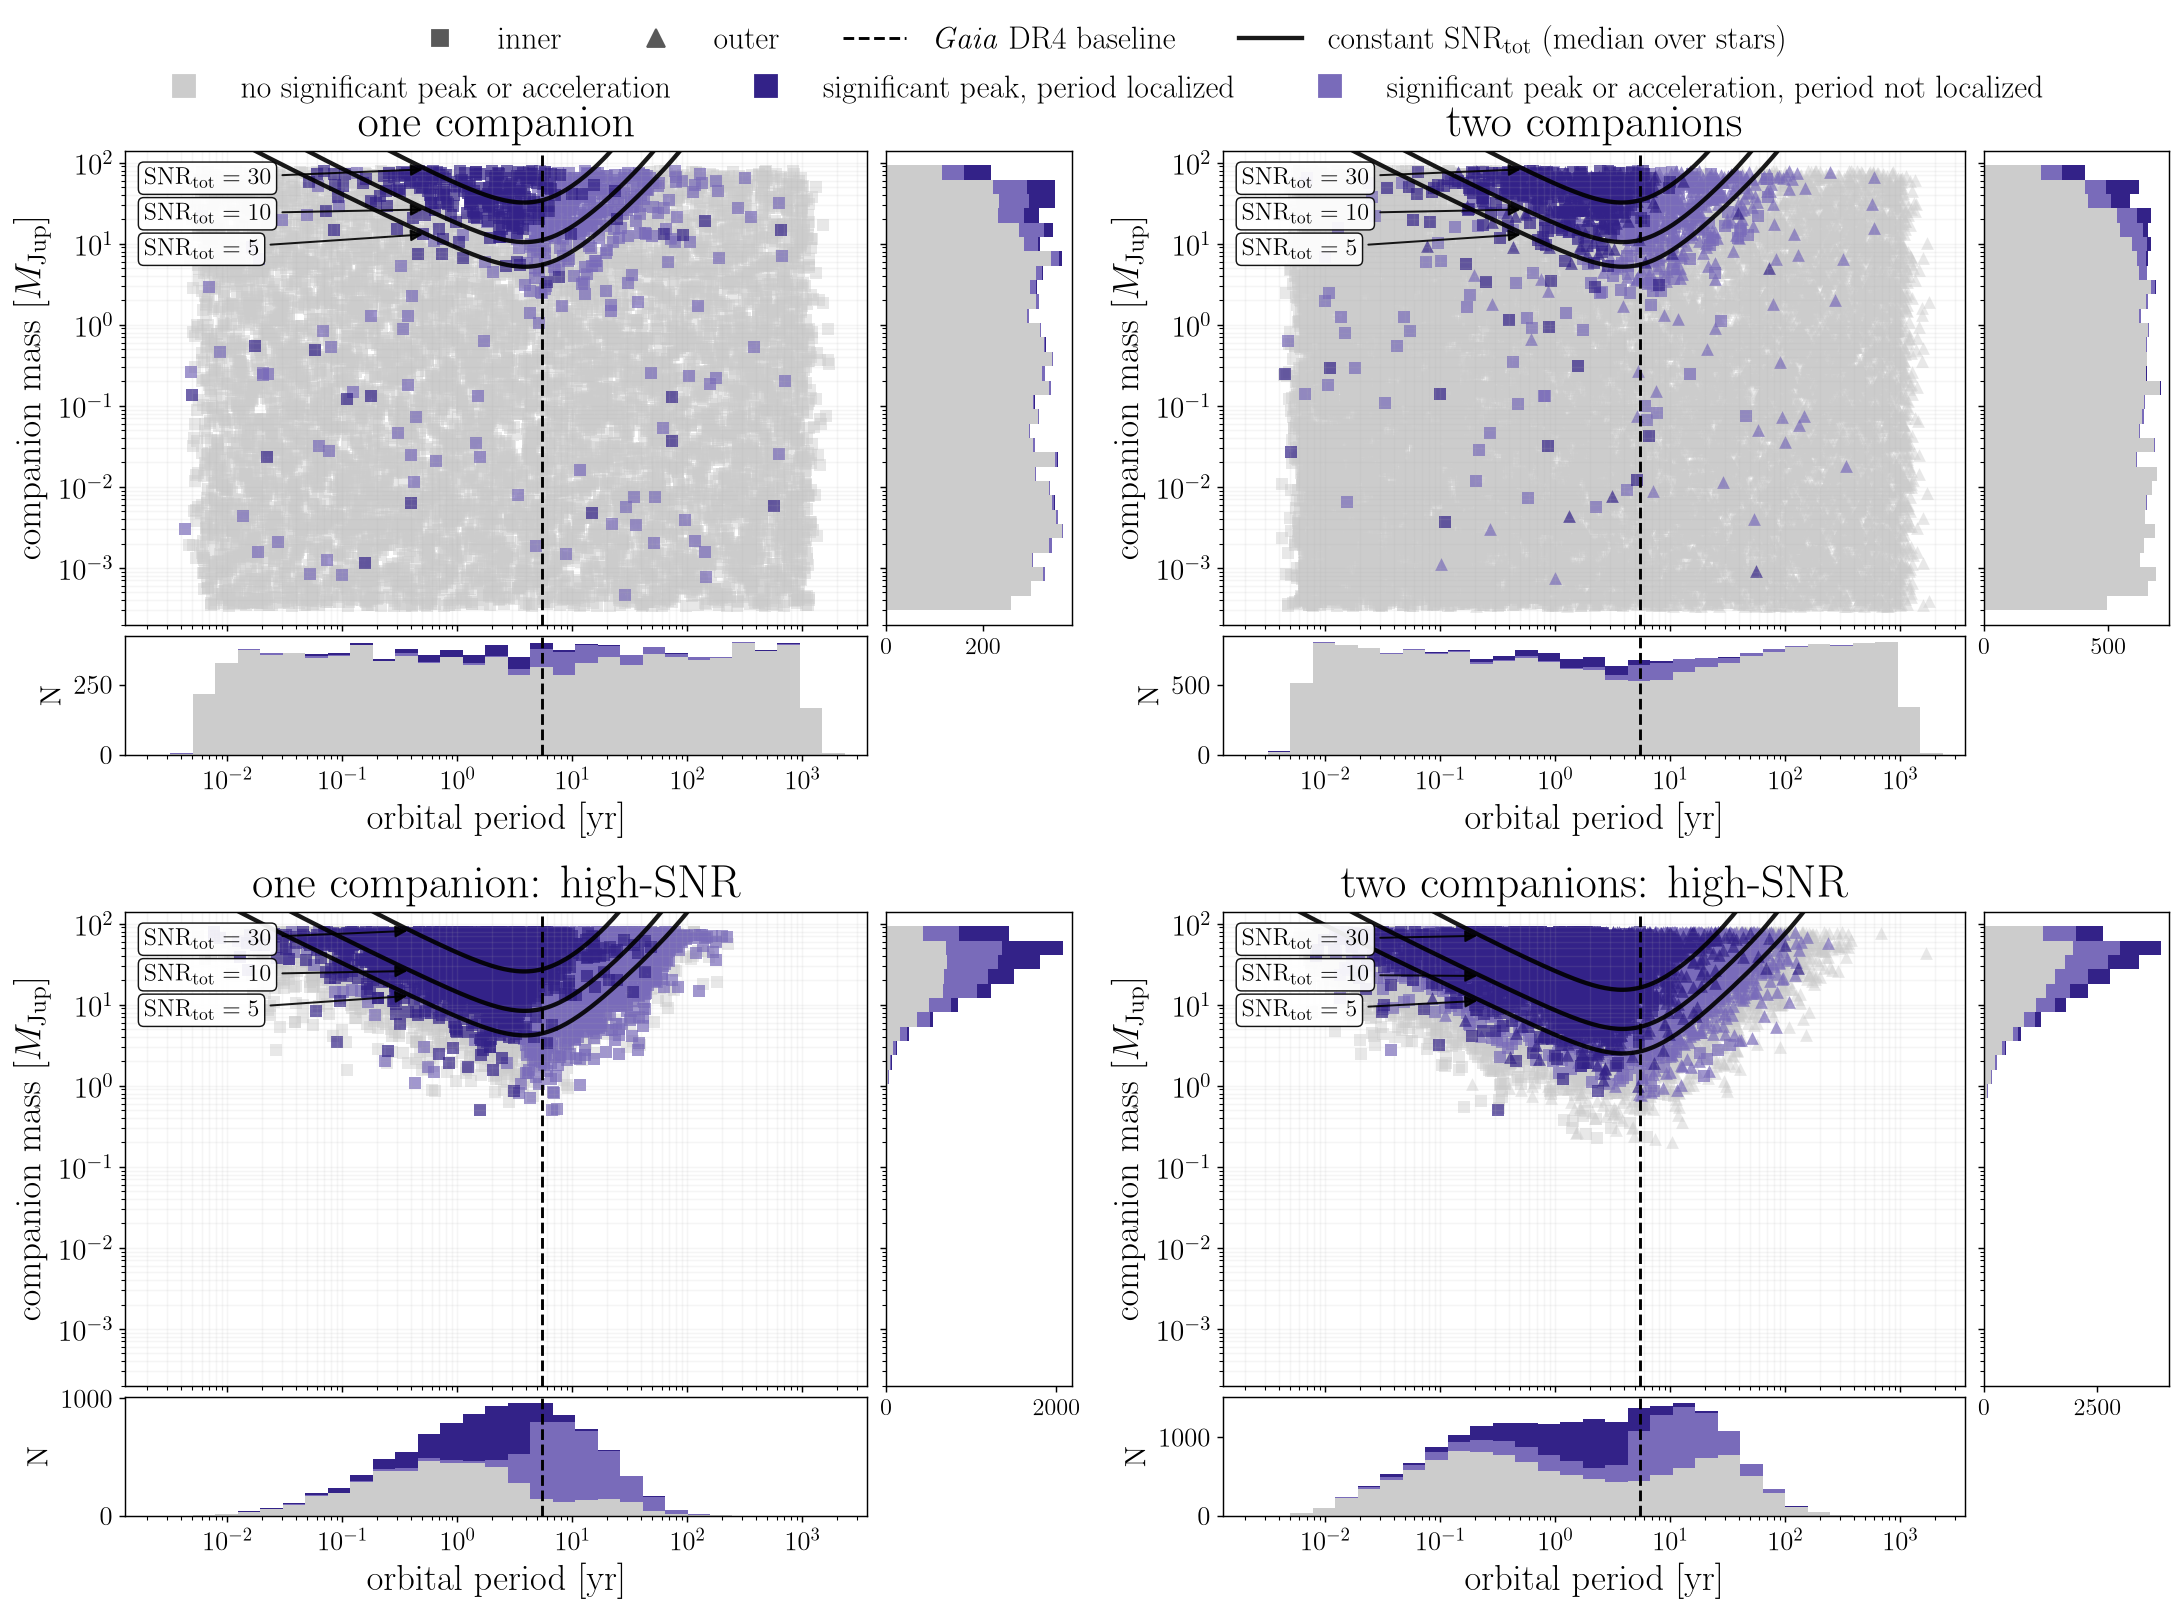

In [8]:
fig = pf.joint(SPECS, AX_P, pf.AX_M, "characterizability_joint", include_undet=True, **JOINT_KW)
plt.close(fig)
display(Image(filename=str(pf.SUPP_FIG_DIR / f"characterizability_joint{FIG_TAG}_wundet.png"), width=1000))

## 5. The paper figure

The margins stack only the two significant classes; the null class remains as the grey background.

  wrote analysis/paper_figures/characterizability_joint_kepmodel_3class_noundet.pdf, analysis/paper_figures/characterizability_joint_kepmodel_3class_noundet.png


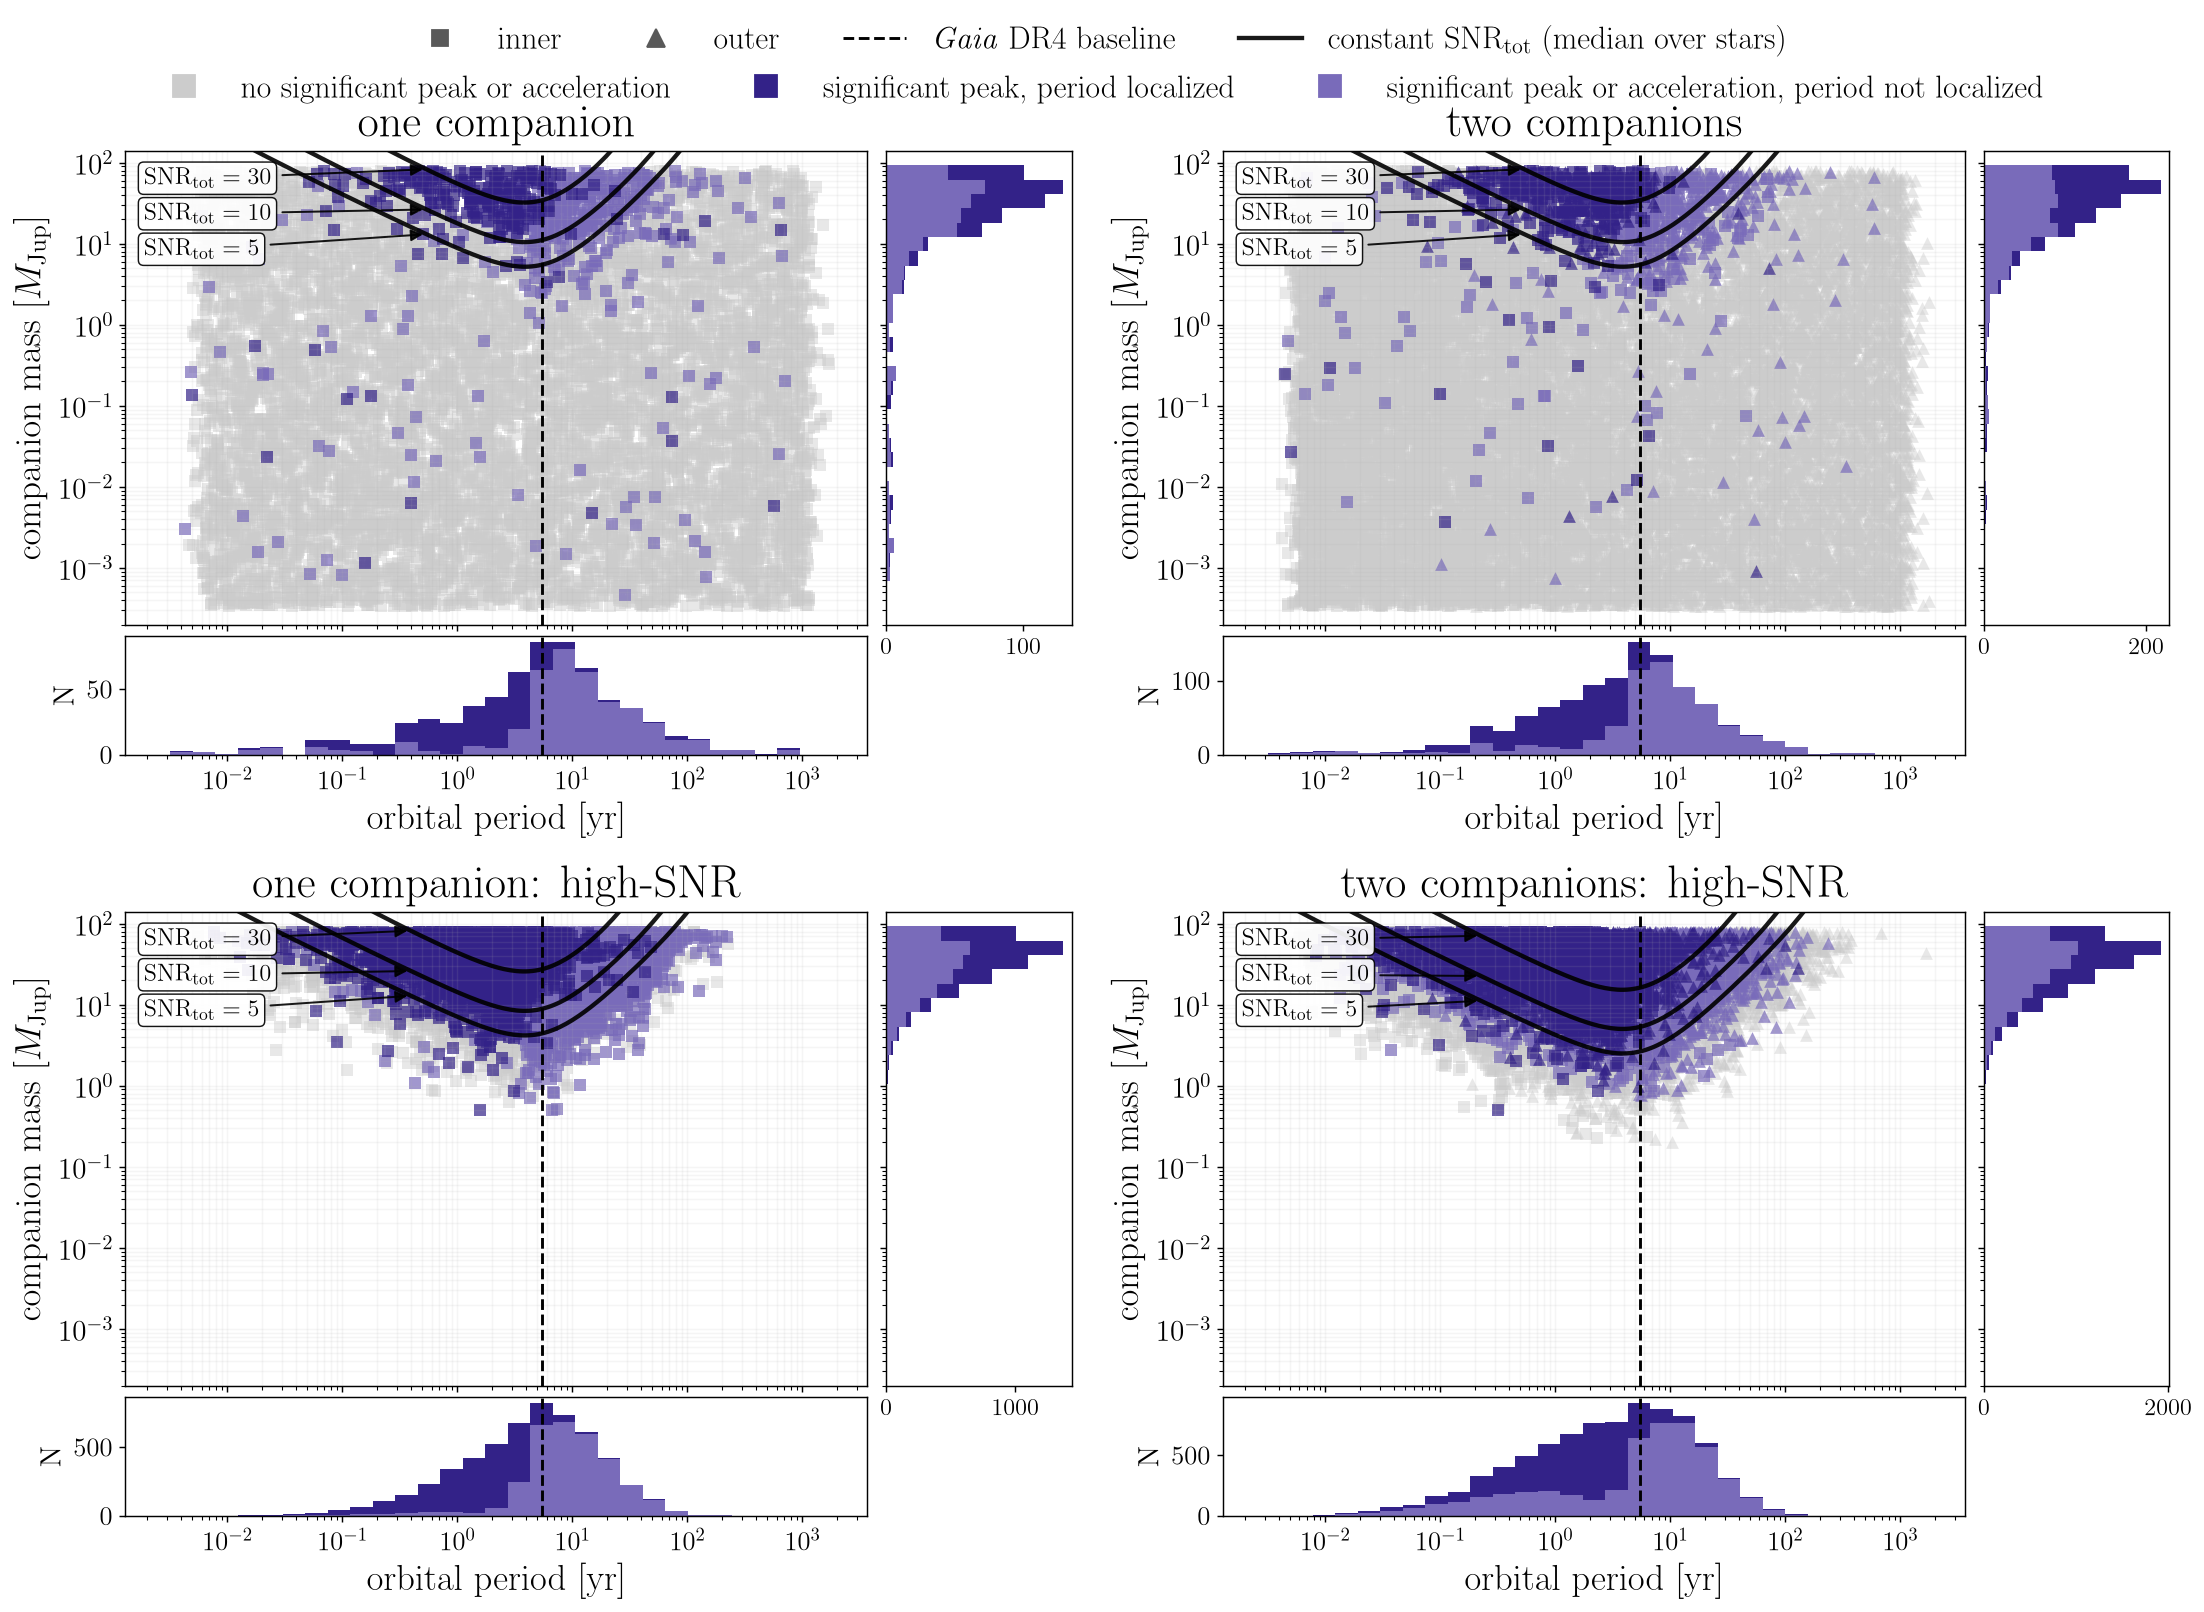

In [9]:
fig = pf.joint(SPECS, AX_P, pf.AX_M, "characterizability_joint", include_undet=False, paper=True, **JOINT_KW)
plt.close(fig)
display(Image(filename=str(pf.PAPER_FIG_DIR / f"characterizability_joint{FIG_TAG}_noundet.png"), width=1000))